# Fast Fashion Industry Dataset: ML Forecasting



In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)


## 1. Data Loading and Inspection

In [ ]:
# Install if required:
# %pip install -q kagglehub[pandas-datasets] xgboost

import kagglehub
from kagglehub import KaggleDatasetAdapter

dataset_id = 'harshinigande/the-fast-fashion-industry-dataset-2000-2023'
dataset_dir = kagglehub.dataset_download(dataset_id)

csv_files = glob.glob(os.path.join(dataset_dir, '**', '*.csv'), recursive=True)
print('Dataset directory:', dataset_dir)
print('CSV files found:', csv_files)

if not csv_files:
    raise FileNotFoundError('No CSV file was found in the Kaggle dataset.')

file_path = os.path.relpath(csv_files[0], dataset_dir)

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    dataset_id,
    file_path
)

print('\nSelected file:', file_path)
print('Shape:', df.shape)
display(df.head())


Using Colab cache for faster access to the 'the-fast-fashion-industry-dataset-2000-2023' dataset.
Dataset directory: /kaggle/input/the-fast-fashion-industry-dataset-2000-2023
CSV files found: ['/kaggle/input/the-fast-fashion-industry-dataset-2000-2023/fast_fashion_data.csv']
Using Colab cache for faster access to the 'the-fast-fashion-industry-dataset-2000-2023' dataset.

Selected file: fast_fashion_data.csv
Shape: (86, 6)


,category,metric,value,unit,year,source
0,employment,Global fashion industry jobs,300.0,million workers,2022,ILO
1,employment,Jobs in developing countries,75.0,percent of workforce,2022,ILO
2,employment,Women employed in garment sector,80.0,percent,2022,ILO
3,employment,Bangladesh garment workers,4.2,million,2022,BGMEA
4,employment,Cambodia garment workers,0.7,million,2022,ILO


In [ ]:
print('Columns:')
print(df.columns.tolist())

display(df.info())
display(df.describe(include='all').T)

missing = df.isna().sum().sort_values(ascending=False)
print('\nMissing values:')
display(missing[missing > 0])

print('Duplicate rows:', df.duplicated().sum())

Columns:
['category', 'metric', 'value', 'unit', 'year', 'source']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  86 non-null     object 
 1   metric    86 non-null     object 
 2   value     86 non-null     float64
 3   unit      86 non-null     object 
 4   year      86 non-null     int64  
 5   source    86 non-null     object 
dtypes: float64(1), int64(1), object(4)
memory usage: 4.2+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
category,86,10,waste,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metric,86,86,Global fashion industry jobs,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
value,86.0,NaN,NaN,NaN,8292.175581,75471.106286,0.7,8.425,15.85,42.725,700000.0
unit,86,12,billion USD,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,86.0,NaN,NaN,NaN,2017.883721,6.402975,2000.0,2015.25,2021.5,2022.0,2023.0
source,86,18,EPA,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,0


Duplicate rows: 0


## 2. Preprocessing and Feature Preparation

In [ ]:
data = df.copy()

# Clean column names and duplicate rows
data.columns = (
    data.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r'[^a-z0-9]+', '_', regex=True)
    .str.strip('_')
)

data = data.drop_duplicates().reset_index(drop=True)

for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].astype(str).str.strip()

data['year'] = pd.to_numeric(data['year'], errors='coerce')
data['value'] = pd.to_numeric(data['value'], errors='coerce')

data = data.dropna(subset=['year', 'value'])

# Select one consistent annual market-size series
market_data = data[
    data['metric'].str.contains(
        'global fast fashion market size',
        case=False,
        na=False
    )
].copy()

market_data = (
    market_data[['year', 'value']]
    .sort_values('year')
    .drop_duplicates()
    .reset_index(drop=True)
)

time_col = 'year'
target = 'value'

print('Forecasting target: Global Fast Fashion Market Size')
print('Unit: billion USD')
print('Observations:', len(market_data))

display(market_data)

Forecasting target: Global Fast Fashion Market Size
Unit: billion USD
Observations: 9


,year,value
0,2015,90.0
1,2016,97.0
2,2017,105.0
3,2018,114.0
4,2019,122.0
5,2020,106.0
6,2021,133.0
7,2022,151.0
8,2023,163.0


## 3. Exploratory Data Analysis

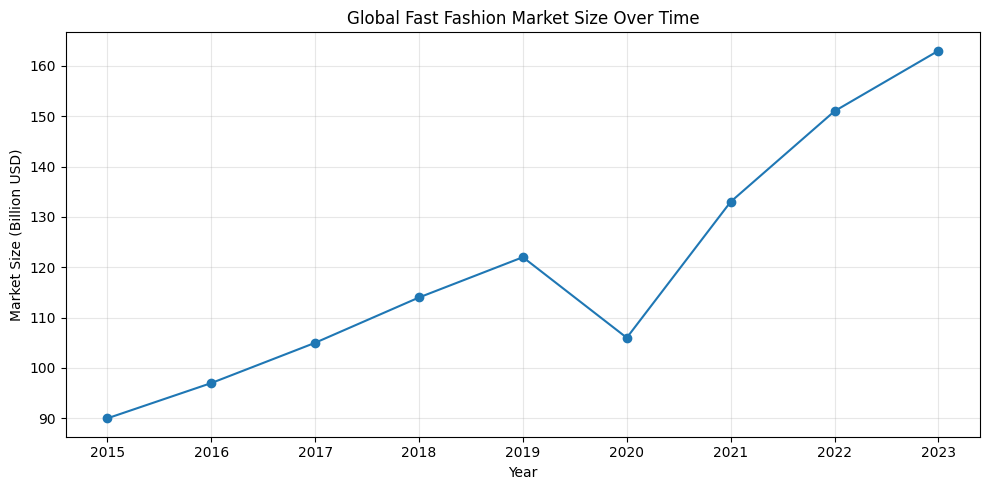

In [ ]:
# Market size trend
plt.figure(figsize=(10, 5))

plt.plot(
    market_data['year'],
    market_data['value'],
    marker='o'
)

plt.title('Global Fast Fashion Market Size Over Time')
plt.xlabel('Year')
plt.ylabel('Market Size (Billion USD)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

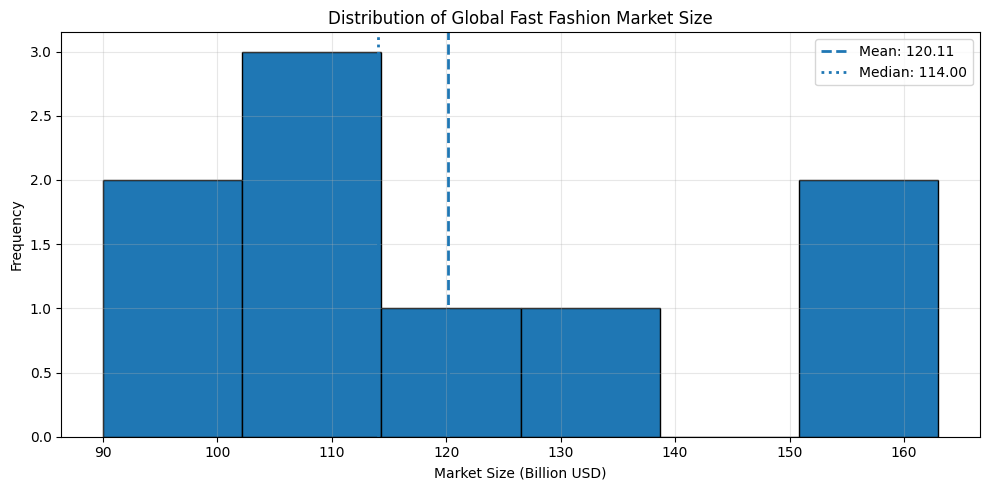

In [ ]:
# Distribution of market size
plt.figure(figsize=(10, 5))

plt.hist(
    market_data['value'].dropna(),
    bins=6,
    edgecolor='black'
)

plt.axvline(
    market_data['value'].mean(),
    linestyle='--',
    linewidth=2,
    label=f"Mean: {market_data['value'].mean():.2f}"
)

plt.axvline(
    market_data['value'].median(),
    linestyle=':',
    linewidth=2,
    label=f"Median: {market_data['value'].median():.2f}"
)

plt.title('Distribution of Global Fast Fashion Market Size')
plt.xlabel('Market Size (Billion USD)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

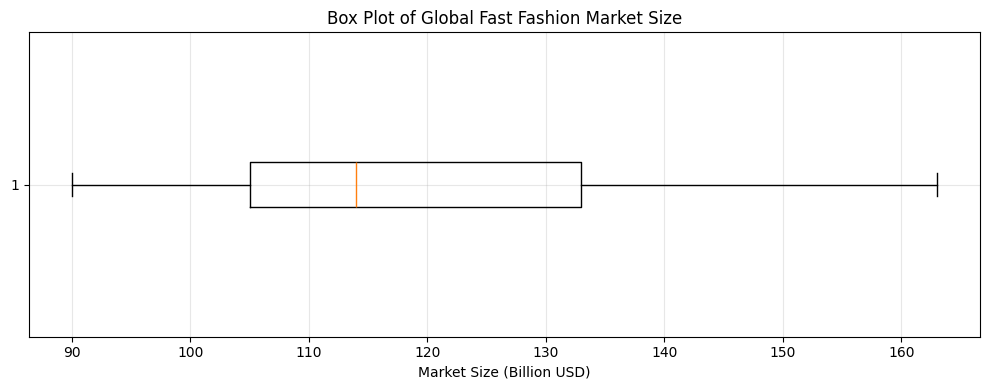

In [ ]:
# Box plot
plt.figure(figsize=(10, 4))

plt.boxplot(
    market_data['value'].dropna(),
    vert=False
)

plt.title('Box Plot of Global Fast Fashion Market Size')
plt.xlabel('Market Size (Billion USD)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

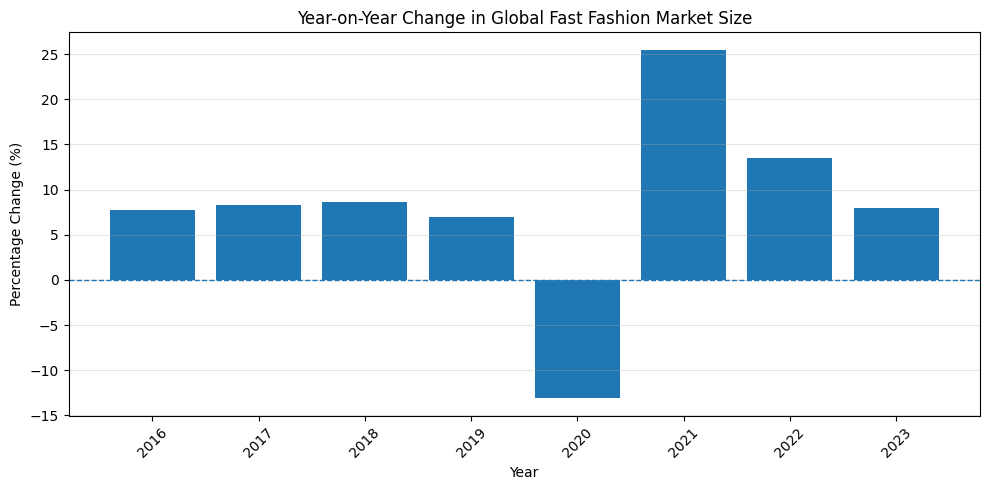

In [ ]:
# Year-on-year market size change
yearly_data = market_data.copy()
yearly_data['percentage_change'] = yearly_data['value'].pct_change() * 100

plt.figure(figsize=(10, 5))

plt.bar(
    yearly_data['year'].astype(str),
    yearly_data['percentage_change']
)

plt.axhline(0, linestyle='--', linewidth=1)
plt.title('Year-on-Year Change in Global Fast Fashion Market Size')
plt.xlabel('Year')
plt.ylabel('Percentage Change (%)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Model Development and Evaluation

In [ ]:

model_data = market_data.copy()

# Create lag and rolling features
model_data['lag_1'] = model_data[target].shift(1)
model_data['lag_2'] = model_data[target].shift(2)

model_data['rolling_mean_2'] = (
    model_data[target]
    .shift(1)
    .rolling(2)
    .mean()
)

model_data = model_data.dropna().reset_index(drop=True)

feature_cols = [
    'lag_1',
    'lag_2',
    'rolling_mean_2'
]

X = model_data[feature_cols]
y = model_data[target]

print('Usable observations:', len(model_data))

# Time-based train-test split
split = int(len(model_data) * 0.70)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print('Training observations:', len(X_train))
print('Testing observations:', len(X_test))

models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        random_state=42
    ),
    'Linear Regression': LinearRegression()
}

try:
    from xgboost import XGBRegressor

    models['XGBoost'] = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42
    )

except ImportError:
    print('XGBoost is not installed. Run: %pip install -q xgboost')

results = []
predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    predictions[name] = pred

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    non_zero = y_test != 0

    if non_zero.any():
        mape = (
            np.mean(
                np.abs(
                    (y_test[non_zero] - pred[non_zero])
                    / y_test[non_zero]
                )
            ) * 100
        )
    else:
        mape = np.nan

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE (%)': mape,
        'R2': r2
    })

results_df = (
    pd.DataFrame(results)
    .sort_values('RMSE')
    .reset_index(drop=True)
)

print('Model Evaluation Results')
display(results_df.round(4))

Usable observations: 7
Training observations: 4
Testing observations: 3
Model Evaluation Results


,Model,MAE,RMSE,MAPE (%),R2
0,Random Forest,36.7022,38.9636,24.0598,-8.9879
1,XGBoost,39.3782,41.8759,25.8085,-10.5368
2,Linear Regression,185.7116,214.6768,131.6015,-302.1983


### Model Comparison and Selection

Selected best model: Random Forest
Selection criterion: lowest RMSE


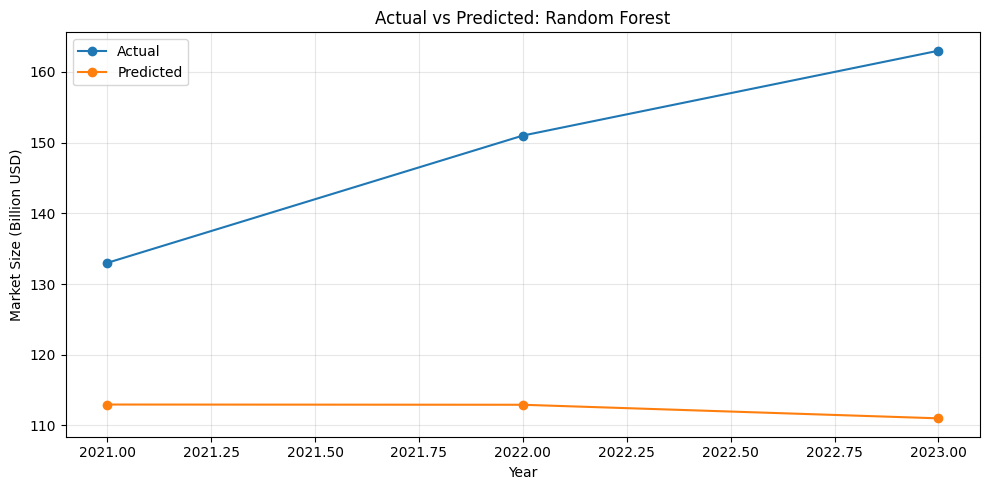

In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
best_pred = predictions[best_model_name]

print('Selected best model:', best_model_name)
print('Selection criterion: lowest RMSE')

plt.figure(figsize=(10, 5))

plt.plot(
    model_data[time_col].iloc[split:],
    y_test.values,
    marker='o',
    label='Actual'
)

plt.plot(
    model_data[time_col].iloc[split:],
    best_pred,
    marker='o',
    label='Predicted'
)

plt.title(f'Actual vs Predicted: {best_model_name}')
plt.xlabel('Year')
plt.ylabel('Market Size (Billion USD)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Forecasting and Feature Importance

Future Market Size Forecast


,year,value
0,2024,157.08
1,2025,157.08
2,2026,157.08
3,2027,157.08
4,2028,157.08


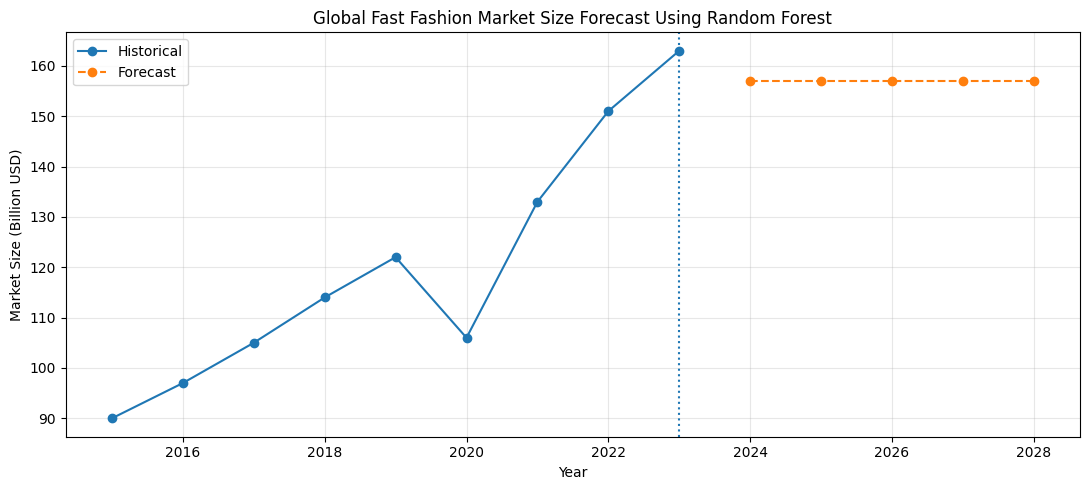

In [ ]:
forecast_steps = 5

history = market_data[
    [time_col, target]
].copy().reset_index(drop=True)

future_rows = []

# Refit the selected model using all available observations
best_model.fit(X, y)

for _ in range(forecast_steps):

    last_values = history[target].tolist()
    next_time = int(history[time_col].iloc[-1] + 1)

    row = {
        'lag_1': last_values[-1],
        'lag_2': last_values[-2],
        'rolling_mean_2': np.mean(last_values[-2:])
    }

    next_input = pd.DataFrame([row])[feature_cols]
    next_pred = best_model.predict(next_input)[0]

    future_rows.append({
        time_col: next_time,
        target: next_pred
    })

    history = pd.concat(
        [
            history,
            pd.DataFrame([{
                time_col: next_time,
                target: next_pred
            }])
        ],
        ignore_index=True
    )

forecast_df = pd.DataFrame(future_rows)

print('Future Market Size Forecast')
display(forecast_df.round(2))

plt.figure(figsize=(11, 5))

plt.plot(
    market_data[time_col],
    market_data[target],
    marker='o',
    label='Historical'
)

plt.plot(
    forecast_df[time_col],
    forecast_df[target],
    marker='o',
    linestyle='--',
    label='Forecast'
)

plt.axvline(
    market_data[time_col].iloc[-1],
    linestyle=':'
)

plt.title(
    f'Global Fast Fashion Market Size Forecast Using {best_model_name}'
)

plt.xlabel('Year')
plt.ylabel('Market Size (Billion USD)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Feature Importance

,Feature,Importance
0,lag_1,0.3659
2,rolling_mean_2,0.3592
1,lag_2,0.2749


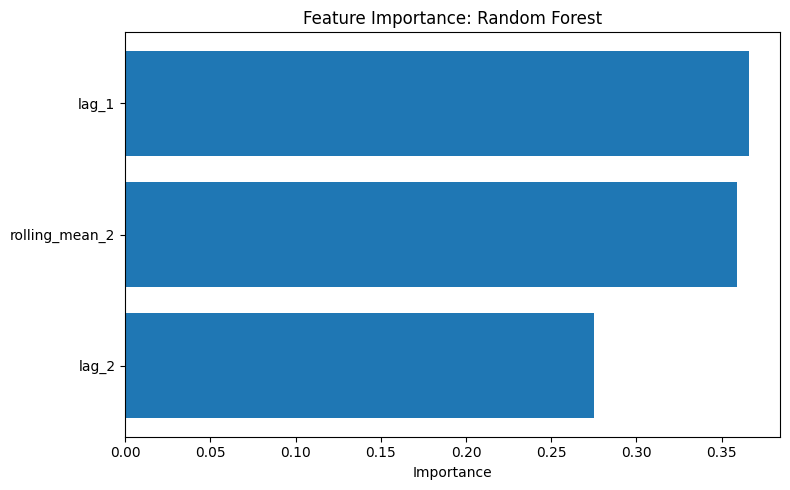

In [ ]:
if hasattr(best_model, 'feature_importances_'):

    importance = pd.DataFrame({
        'Feature': feature_cols,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    display(importance.round(4))

    plt.figure(figsize=(8, 5))

    plt.barh(
        importance['Feature'][::-1],
        importance['Importance'][::-1]
    )

    plt.title(f'Feature Importance: {best_model_name}')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()